In [7]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

In [3]:
DATA_DIR <- "/home/mariya/Data/pallas"
TRAIN_DATA_DIR <- file.path(DATA_DIR, "nf-core-mlomix-train-bimodal/finalize")
METH_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.dnam.csv")
GEX_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "features.gex.csv")
LABELS_TRAIN_FILE <- file.path(TRAIN_DATA_DIR, "labels.csv")

In [4]:
data <- function(gex_file, dnam_file, labels_file) {
    # --- Read in data ---
    X_gex  <- read.csv(gex_file,    row.names = 1, check.names = FALSE)
    X_dnam <- read.csv(dnam_file,   row.names = 1, check.names = FALSE)
    labels <- read.csv(labels_file, row.names = 1)

    # --- Extract Y as a factor ---
    # Replace "subtype" with your actual column name
    Y <- factor(labels[, "class"])

    # --- Align sample order across all three ---
    # (critical — mixOmics assumes rows are in the same order)
    common_samples <- Reduce(intersect, list(rownames(X_gex),
                                            rownames(X_dnam),
                                            rownames(labels)))

    X_gex  <- as.matrix(X_gex[common_samples, ])
    X_dnam <- as.matrix(X_dnam[common_samples, ])
    Y      <- Y[match(common_samples, rownames(labels))]

    # --- Sanity checks ---
    stopifnot(nrow(X_gex)  == length(Y))
    stopifnot(nrow(X_dnam) == length(Y))
    stopifnot(all(rownames(X_gex) == rownames(X_dnam)))

    cat("Samples:", length(Y), "\n")
    cat("GEX features:", ncol(X_gex), "\n")
    cat("DNAm features:", ncol(X_dnam), "\n")
    cat("Subtypes:", levels(Y), "\n")
    return(list(X_gex = X_gex, X_dnam = X_dnam, Y = Y))
}

train_data <- data(GEX_TRAIN_FILE, METH_TRAIN_FILE, LABELS_TRAIN_FILE)

Samples: 827 
GEX features: 5000 
DNAm features: 5000 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [5]:
X_gex_train <- train_data$X_gex
X_dnam_train <- train_data$X_dnam
Y_train     <- train_data$Y

head(X_gex_train)
head(X_dnam_train)
head(Y_train)

,ENSG00000254772,ENSG00000196230,ENSG00000136167,ENSG00000120129,ENSG00000152518,ENSG00000108849,ENSG00000147127,ENSG00000130066,ENSG00000145741,ENSG00000116703,⋯,ENSG00000173207,ENSG00000139793,ENSG00000167797,ENSG00000110987,ENSG00000100162,ENSG00000142327,ENSG00000130770,ENSG00000168824,ENSG00000275066,ENSG00000150093
TARGET-20-PASWLN-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,7.968453,8.201993,-1.110315,-1.110315,7.629022,⋯,3.329529,6.377667,4.155871,5.503012,1.437385,3.416764,5.593546,1.5736289,5.615856,4.932075
TARGET-20-PAVNHN-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,9.651507,8.238651,-1.110315,-1.110315,8.743245,⋯,3.325243,4.998404,3.889626,2.388745,5.188508,6.753050,4.478985,-0.4569365,5.244575,4.588830
TARGET-20-PARURW-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,7.430994,9.591533,-1.110315,-1.110315,9.646101,⋯,6.390863,5.110798,6.692811,5.357277,4.683748,5.425402,8.064418,0.1519207,3.498843,4.158064
TARGET-20-PAPVKG-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,7.851423,9.648369,-1.110315,-1.110315,9.552824,⋯,7.075817,4.355816,6.616366,4.077949,5.673264,6.049784,7.412941,-0.1748666,4.167821,6.556703
TARGET-20-PASJDV-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,8.570422,9.675942,-1.110315,-1.110315,10.000632,⋯,4.323619,3.286130,6.892616,6.783589,3.792690,8.109676,7.042379,0.3849265,4.073624,6.144524
TARGET-20-PASAFH-D,-1.110315,-1.110315,-1.110315,-1.110315,-1.110315,8.277945,9.758931,-1.110315,-1.110315,10.104308,⋯,4.218665,5.559829,5.762059,6.228017,2.297075,6.620060,7.076211,0.8439528,4.406055,5.124707


,cg09698465,cg20439288,cg07110356,cg17353893,cg25670583,cg18559579,cg25588389,cg01030534,cg22301418,cg23478547,⋯,cg14293575,cg24563570,cg13931640,cg20722088,cg21531416,cg12103569,cg25970575,cg09187505,cg20165746,cg10725937
TARGET-20-PASWLN-D,0.9795,0.9637,0.9845,0.9739,0.9769,0.0258,0.9759,0.9759,0.9816,0.3976,⋯,0.9487,0.3689,0.9881,0.9521,0.9635,0.8681,0.2758,0.8247,0.0972,0.2172
TARGET-20-PAVNHN-D,0.4319,0.0347,0.0686,0.8751,0.3817,0.7416,0.0349,0.1404,0.5413,0.0383,⋯,0.6504,0.5236,0.8780,0.8355,0.8787,0.8327,0.7544,0.9197,0.1737,0.0928
TARGET-20-PARURW-D,0.9071,0.7292,0.1595,0.3500,0.2146,0.2064,0.1724,0.5086,0.2486,0.2907,⋯,0.8048,0.5735,0.3990,0.8588,0.4571,0.0973,0.4581,0.3174,0.8437,0.4610
TARGET-20-PAPVKG-D,0.5056,0.8414,0.0658,0.2899,0.1558,0.0576,0.2374,0.8892,0.1917,0.1229,⋯,0.9216,0.5348,0.3080,0.4343,0.4585,0.1123,0.6375,0.8231,0.8716,0.2129
TARGET-20-PASJDV-D,0.9710,0.8416,0.9605,0.9837,0.9580,0.9554,0.9494,0.8966,0.4994,0.9774,⋯,0.7699,0.7911,0.5653,0.9253,0.8863,0.0479,0.2803,0.9693,0.8632,0.4679
TARGET-20-PASAFH-D,0.8489,0.8338,0.0610,0.8793,0.0845,0.0668,0.9418,0.0619,0.0837,0.5277,⋯,0.4154,0.3757,0.3313,0.1368,0.3899,0.0702,0.0953,0.6072,0.7669,0.4770


[1] AML, KMT2A-r        AML, KMT2A-r        AML, RUNX1::RUNX1T1
[4] AML, RUNX1::RUNX1T1 AML, NUP98-r        AML, RUNX1::RUNX1T1
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

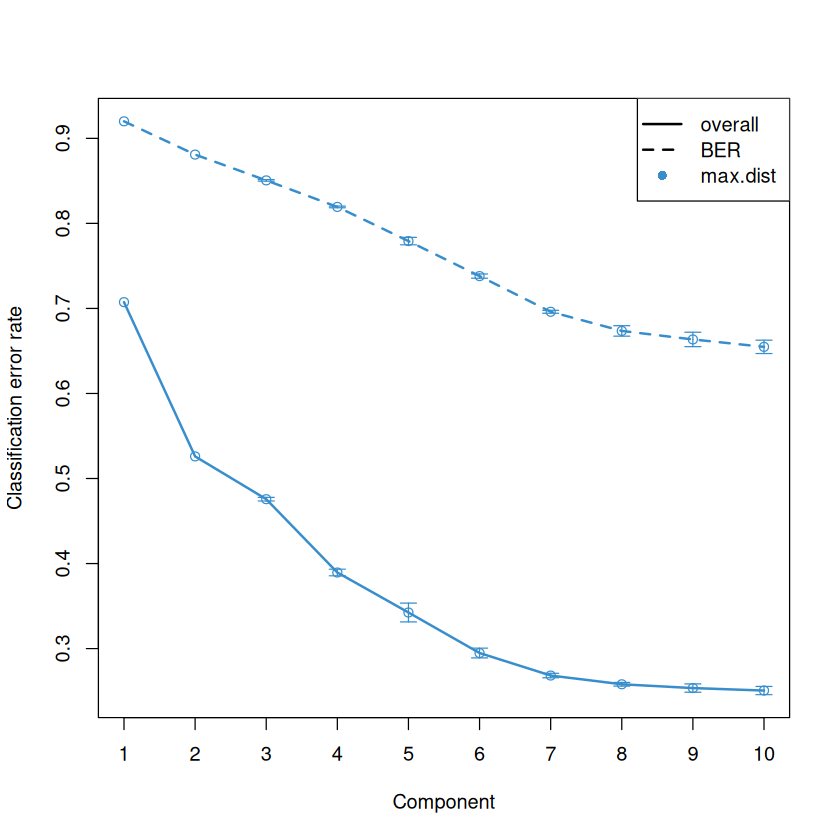

In [12]:
FOLDS      <- 5
NREPEAT    <- 10
MAX_NCOMP  <- 10   # increased from 5
bpparam <- MulticoreParam(workers = parallel::detectCores() - 1)

gex_prelim <- splsda(X_gex_train, Y_train,
                     ncomp = MAX_NCOMP,
                     keepX = rep(200, MAX_NCOMP))
gex_perf   <- perf(gex_prelim,
                   validation  = "Mfold",
                   folds       = FOLDS,
                   nrepeat     = NREPEAT,
                   dist        = "max.dist",
                   BPPARAM     = bpparam,
                   progressBar = FALSE)

# Plot BER across all components to see the curve shape
plot(gex_perf, criterion = "BER")